# From Bootstrap to Asymptotic Inference

## Introduction
- We're going to show how you can approximate non-parametric bootstrap inference by using the Normal distribution
- Our running example will be **hedonic pricing**: predicting the value of housing based on its amenities (square feet, bathrooms, total rooms, area, age)

## 1. Sampling the Sampling Distribution
- You have covered OLS/linear regression in ML1, so we can play with it here
- We'll use the Ames housing price data, and run a simple regression:
$$
\begin{alignat*}{2}
\widehat{\log(\text{price})}_i &=& \text{const} + \beta_{\text{area}} \log(\text{area}_i) + \beta_{\text{age}} \log(\text{age}_i) \\
&&+ \sum_k \beta_{\text{rooms}= k} \text{rooms}_{i, k} + \sum_k \beta_{\text{quality}= k} \text{quality}_{i, k}
+ \sum_k \beta_{\text{baths} = k} \text{baths}_{i, k} 
\end{alignat*}
$$
- The second line are all one-hot encoded/dummy, and the first like are continuous/numeric variables
- We'll resample the data $(X,y)$, running this regression thousands of times and caching the coefficients

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import seaborn as sns 

from scipy.stats import norm

df = pd.read_csv('./data/ames_prices.csv')
df.head()

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
0,1,526301100,1656,215000,20,RL,141.0,31770,Pave,NaN,...,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
1,2,526350040,896,105000,20,RH,80.0,11622,Pave,NaN,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
2,3,526351010,1329,172000,20,RL,81.0,14267,Pave,NaN,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
3,4,526353030,2110,244000,20,RL,93.0,11160,Pave,NaN,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,5,527105010,1629,189900,60,RL,74.0,13830,Pave,NaN,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal


<Axes: xlabel='price', ylabel='Density'>

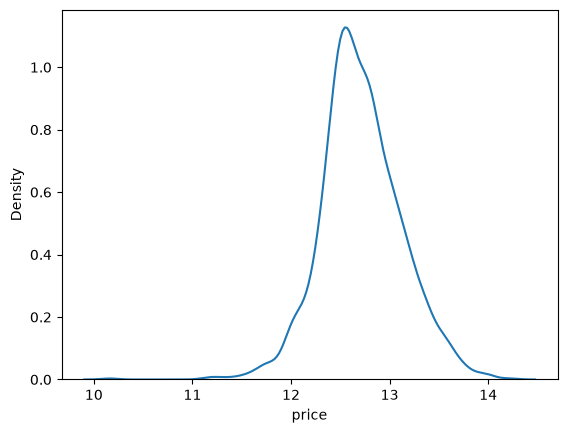

In [2]:
sns.kdeplot( np.arcsinh(df['price']) )

In [3]:
df = df.drop(['Pool.QC', 'Misc.Feature', 'Pool.QC','Alley', 'Fence', 
              'Mas.Vnr.Type', 'Fireplace.Qu',
         'Lot.Frontage', ], axis =1)
df.head()
df['age'] = df['Year.Built'].max() - df['Year.Built']
df['Garage.Type'] = df['Garage.Type'].fillna('None')

In [4]:
df.columns

Index(['Order', 'PID', 'area', 'price', 'MS.SubClass', 'MS.Zoning', 'Lot.Area',
       'Street', 'Lot.Shape', 'Land.Contour', 'Utilities', 'Lot.Config',
       'Land.Slope', 'Neighborhood', 'Condition.1', 'Condition.2', 'Bldg.Type',
       'House.Style', 'Overall.Qual', 'Overall.Cond', 'Year.Built',
       'Year.Remod.Add', 'Roof.Style', 'Roof.Matl', 'Exterior.1st',
       'Exterior.2nd', 'Mas.Vnr.Area', 'Exter.Qual', 'Exter.Cond',
       'Foundation', 'Bsmt.Qual', 'Bsmt.Cond', 'Bsmt.Exposure',
       'BsmtFin.Type.1', 'BsmtFin.SF.1', 'BsmtFin.Type.2', 'BsmtFin.SF.2',
       'Bsmt.Unf.SF', 'Total.Bsmt.SF', 'Heating', 'Heating.QC', 'Central.Air',
       'Electrical', 'X1st.Flr.SF', 'X2nd.Flr.SF', 'Low.Qual.Fin.SF',
       'Bsmt.Full.Bath', 'Bsmt.Half.Bath', 'Full.Bath', 'Half.Bath',
       'Bedroom.AbvGr', 'Kitchen.AbvGr', 'Kitchen.Qual', 'TotRms.AbvGrd',
       'Functional', 'Fireplaces', 'Garage.Type', 'Garage.Yr.Blt',
       'Garage.Finish', 'Garage.Cars', 'Garage.Area', 'Garage.Qual

In [5]:
df.isna().sum().sort_values(ascending=False)[:25]

Garage.Finish      159
Garage.Qual        159
Garage.Cond        159
Garage.Yr.Blt      159
Bsmt.Exposure       83
BsmtFin.Type.2      81
Bsmt.Qual           80
Bsmt.Cond           80
BsmtFin.Type.1      80
Mas.Vnr.Area        23
Bsmt.Half.Bath       2
Bsmt.Full.Bath       2
Garage.Cars          1
BsmtFin.SF.1         1
BsmtFin.SF.2         1
Bsmt.Unf.SF          1
Total.Bsmt.SF        1
Electrical           1
Garage.Area          1
Enclosed.Porch       0
X2nd.Flr.SF          0
Low.Qual.Fin.SF      0
Sale.Condition       0
Sale.Type            0
Yr.Sold              0
dtype: int64

In [6]:
outcome_var = ['price']
num_vars = ['TotRms.AbvGrd', ]
num_ihs_vars = [ #'Wood.Deck.SF', 
                #'Total.Bsmt.SF', 
                'age', 
                'area']
cat_vars = [#'Overall.Qual', 
            'Full.Bath', 
            #'Half.Bath', 
            #'Fireplaces',
            #'Kitchen.Qual', 
            #'Garage.Cars', 
            #'Neighborhood',
            #'Exter.Qual',
            #'Garage.Type',
            ]

rdf = df.loc[:,outcome_var + num_vars + num_ihs_vars + cat_vars].dropna()

X = rdf.loc[:,num_vars]
for var in num_ihs_vars:
    X = pd.concat( [ X, np.arcsinh(rdf[var])], axis = 1)
for var in cat_vars:
    X = pd.concat( [ X, pd.get_dummies(rdf[var], dtype = int, drop_first = True, prefix=var)], axis = 1 )

### Add intercept:
X.insert(0, 'const', 1.0)
y = np.arcsinh( rdf['price'] )


In [7]:
def mlr(X,y):
    reg = np.linalg.lstsq(X, y, rcond=None)
    beta_hat = reg[0]
    return beta_hat
beta_hat = mlr(X,y)
print(beta_hat)

[ 6.40268240e+00 -3.87494945e-02 -1.70000602e-01  9.11096853e-01
  5.65054343e-03 -5.74256317e-02  5.35178964e-02 -2.87170320e-01]


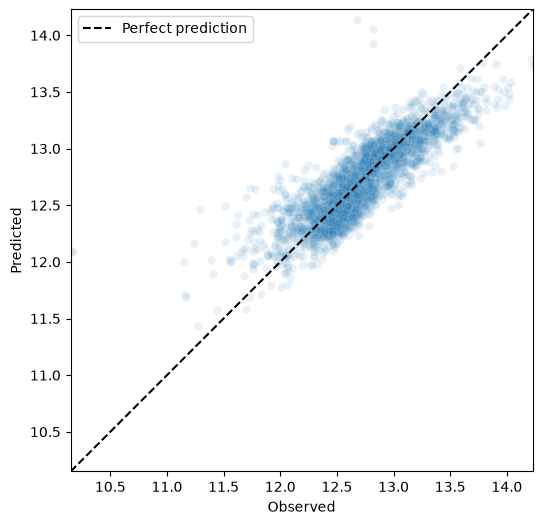

In [8]:
y_hat = X @ beta_hat # Make predictions

fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(x=y, y= y_hat, alpha=0.1, ax=ax)
lims = [
    min(np.min(y), np.min(y_hat)),
    max(np.max(y), np.max(y_hat))
]
ax.plot(lims, lims, 'k--', linewidth=1.5, label='Perfect prediction')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('Observed')
ax.set_ylabel('Predicted')
ax.legend()
plt.show()

In [9]:
R = 1_000
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(rdf), len(rdf))
    beta_hat_t = mlr(X.iloc[idx], y.iloc[idx])
    results.append(beta_hat_t)
results = np.array(results)

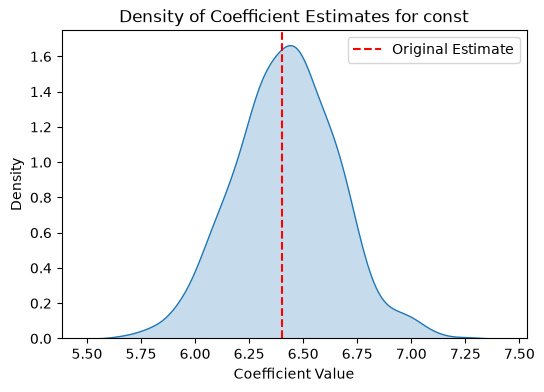

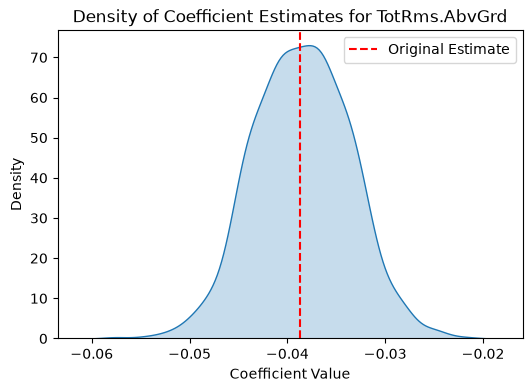

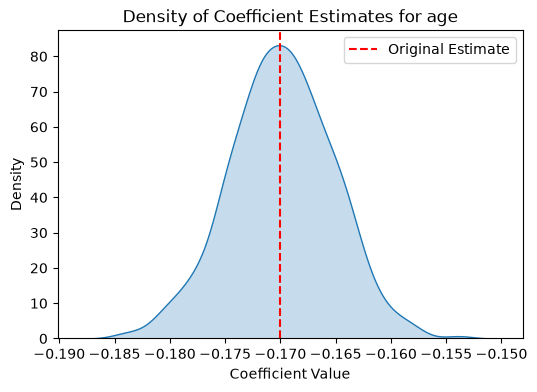

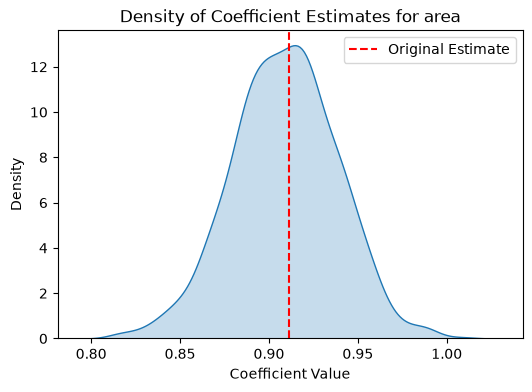

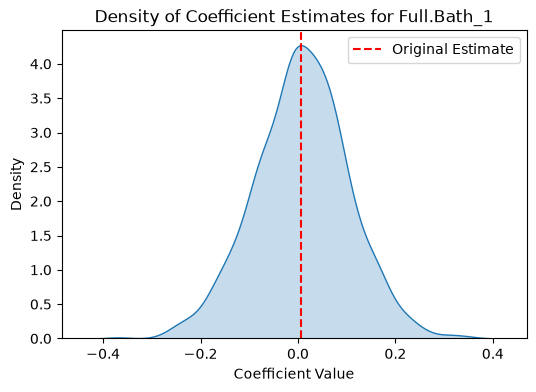

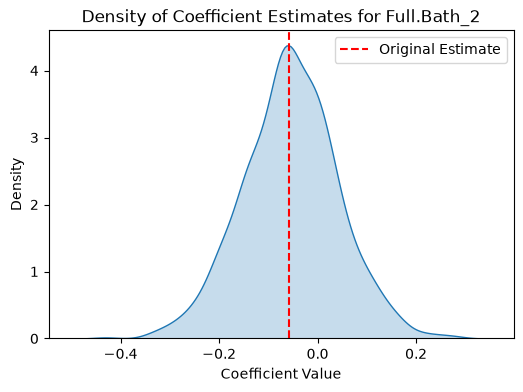

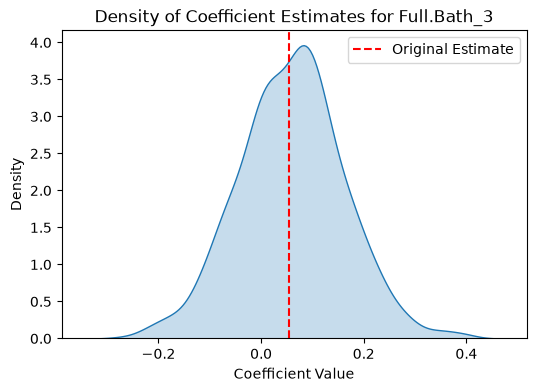

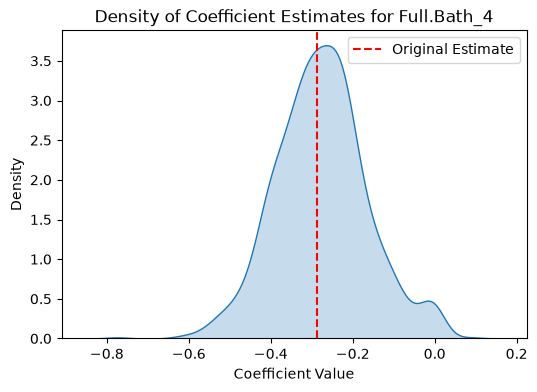

In [10]:
vars = X.columns.to_list()
for idx, var in enumerate(vars):
    plt.figure(figsize=(6, 4))
    sns.kdeplot(results[:, idx], fill=True)
    plt.axvline(beta_hat[idx], color='red', linestyle='--', label='Original Estimate')
    plt.title(f'Density of Coefficient Estimates for {var}')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Density')
    plt.legend()
    plt.show()

## 2. Fitting the Bootstrapped Sampling Distribution

What if we overlayed a normal with the **bootstrap mean** 
$$
\bar{\beta}_{\text{boot}} = \frac{1}{R} \sum_{b=1}^R \hat{\beta}_b
$$
and the standard deviation of the bootstrap sample --- which is our estimate of the **standard error** ---
$$
\widehat{\text{SE}}(\hat{\beta})= \sqrt{ \frac{1}{R-1}\sum_{b=1}^R (\hat{\beta}_b-\bar{\beta}_{\text{boot}})^2}?
$$

90% Confidence Interval for const: [6.0275, 6.7928]
95% Confidence Interval for const: [5.9516, 6.9027]
99% Confidence Interval for const: [5.7942, 7.0326]


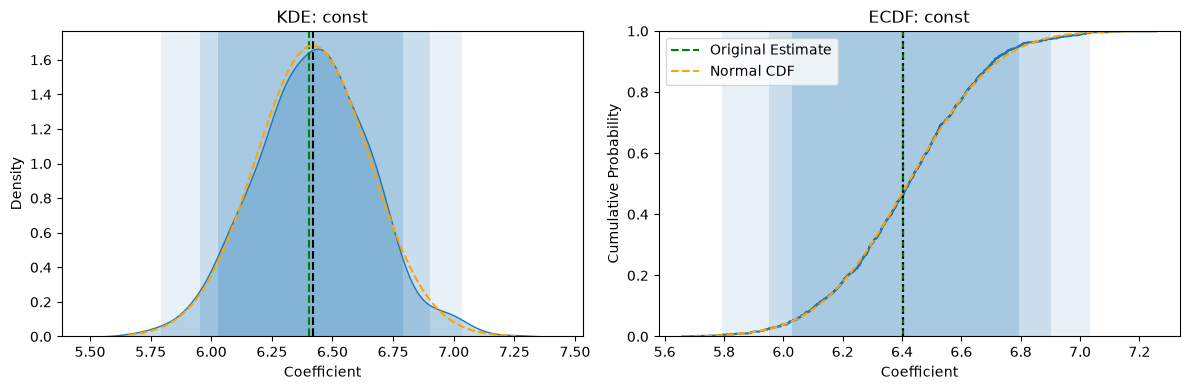

90% Confidence Interval for TotRms.AbvGrd: [-0.0461, -0.0306]
95% Confidence Interval for TotRms.AbvGrd: [-0.0479, -0.0288]
99% Confidence Interval for TotRms.AbvGrd: [-0.0517, -0.0255]


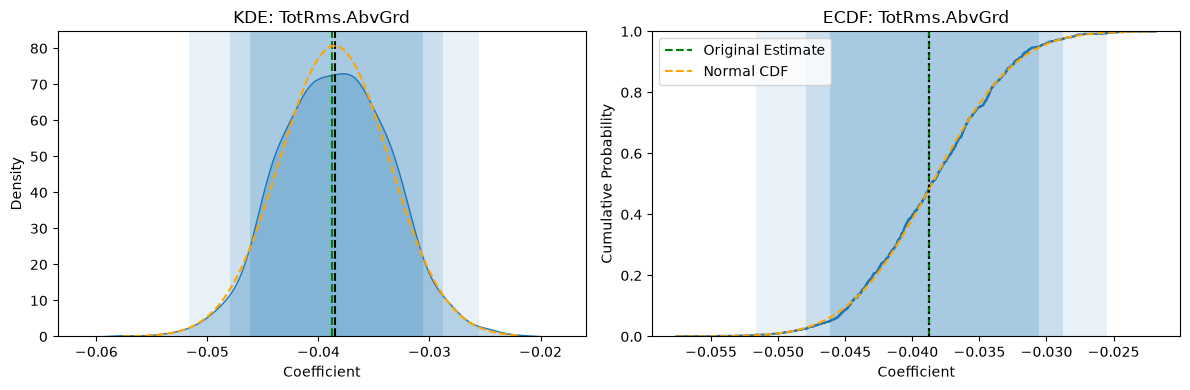

90% Confidence Interval for age: [-0.1777, -0.1625]
95% Confidence Interval for age: [-0.1794, -0.1609]
99% Confidence Interval for age: [-0.1824, -0.1581]


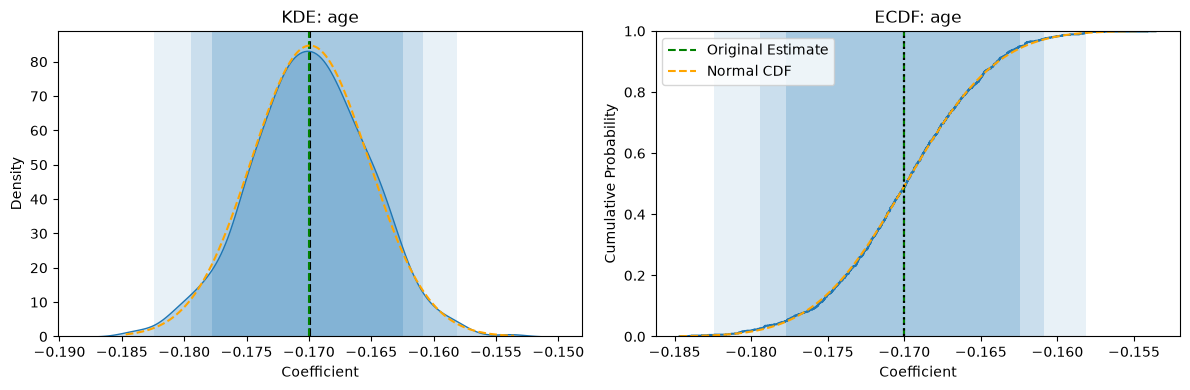

90% Confidence Interval for area: [0.8616, 0.9557]
95% Confidence Interval for area: [0.8498, 0.9632]
99% Confidence Interval for area: [0.8316, 0.9875]


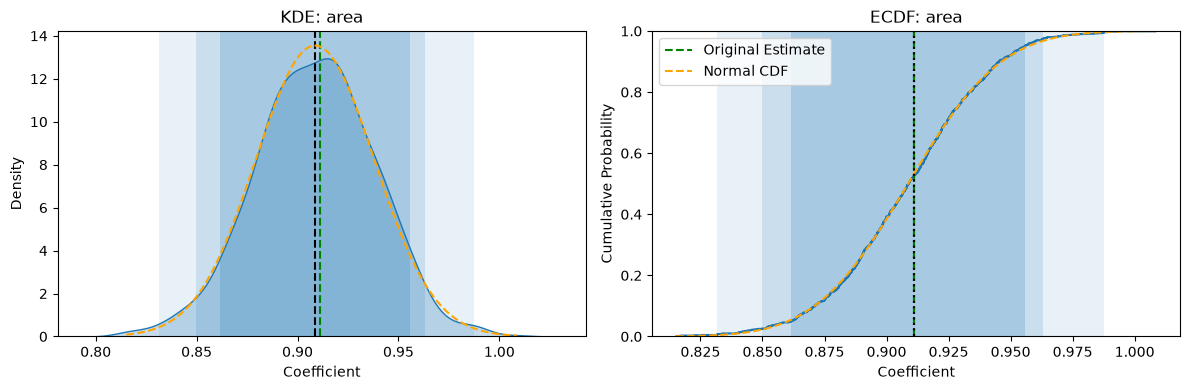

90% Confidence Interval for Full.Bath_1: [-0.1530, 0.1665]
95% Confidence Interval for Full.Bath_1: [-0.1813, 0.1951]
99% Confidence Interval for Full.Bath_1: [-0.2496, 0.2624]


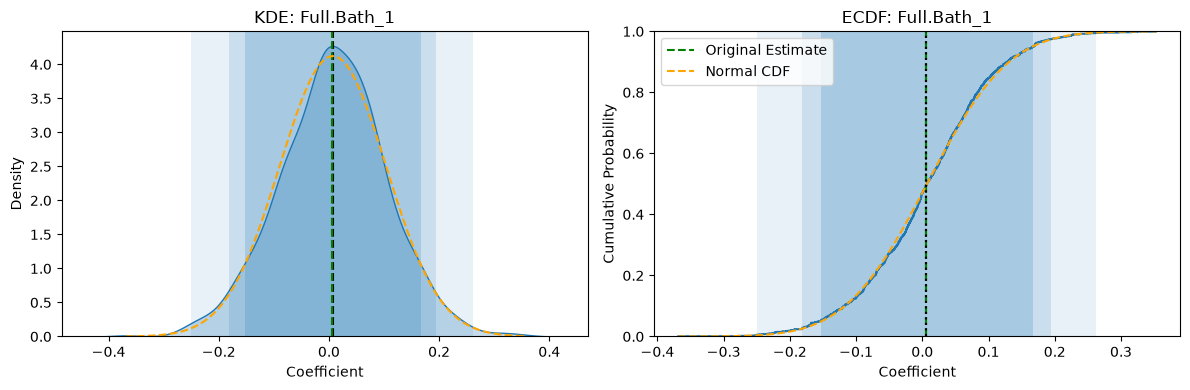

90% Confidence Interval for Full.Bath_2: [-0.2137, 0.1029]
95% Confidence Interval for Full.Bath_2: [-0.2472, 0.1349]
99% Confidence Interval for Full.Bath_2: [-0.3107, 0.2127]


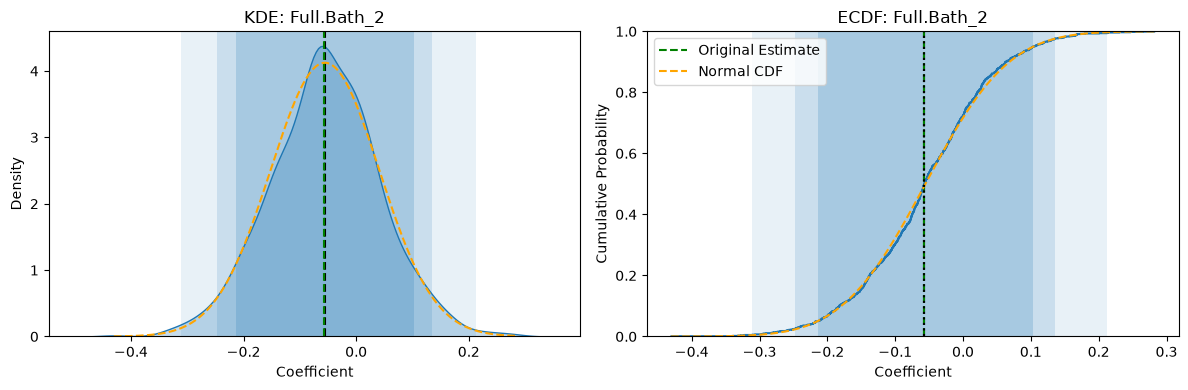

90% Confidence Interval for Full.Bath_3: [-0.1084, 0.2267]
95% Confidence Interval for Full.Bath_3: [-0.1411, 0.2617]
99% Confidence Interval for Full.Bath_3: [-0.2087, 0.3493]


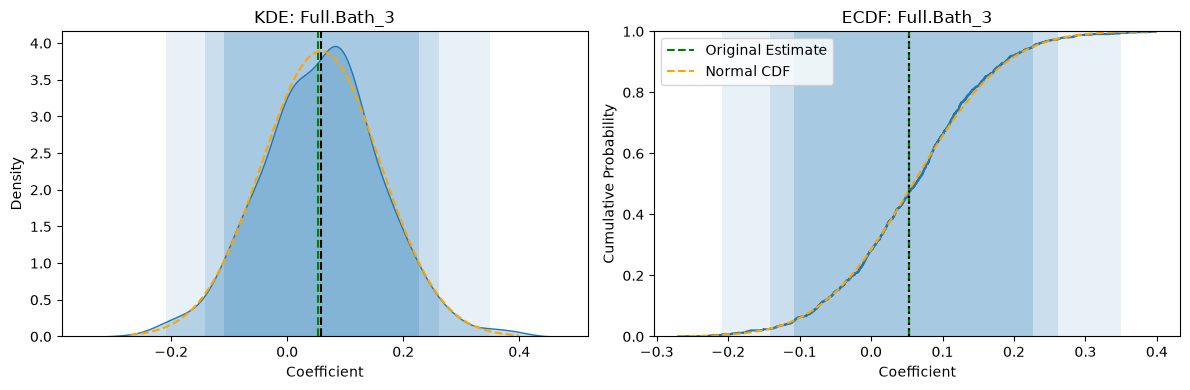

90% Confidence Interval for Full.Bath_4: [-0.4514, -0.0874]
95% Confidence Interval for Full.Bath_4: [-0.4973, -0.0175]
99% Confidence Interval for Full.Bath_4: [-0.5633, 0.0000]


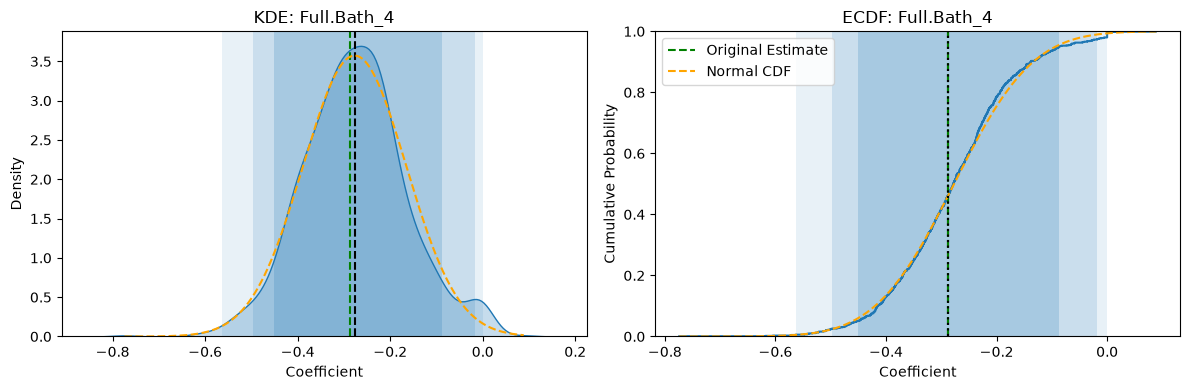

In [11]:
vars = X.columns.to_list()

for idx, var in enumerate(vars):
    sample = results[:, idx]
    mean = np.mean(sample)
    standard_error = np.std(sample, ddof=1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # KDE
    sns.kdeplot(sample, fill=True, ax=ax[0])
    ax[0].axvline(mean, color='black', linestyle='--')
    ax[0].set_title(f'KDE: {var}')
    ax[0].set_xlabel('Coefficient')
    ax[0].set_ylabel('Density')
    ax[0].axvline(beta_hat[idx], color='green', linestyle='--',
        label='Original Estimate')
    x_grid = np.linspace(sample.min(), sample.max(), 500)
    ax[0].plot(
        x_grid,
        norm.pdf(x_grid, loc=mean, scale=standard_error),
        color='orange',
        linestyle='--',
        label='Normal PDF'
    )
    
    # ECDF
    sns.ecdfplot(sample, ax=ax[1])
    ax[1].axvline(beta_hat[idx], color='black', linestyle='--')
    ax[1].set_title(f'ECDF: {var}')
    ax[1].set_xlabel('Coefficient')
    ax[1].set_ylabel('Cumulative Probability')
    ax[1].set_ylim(0, 1)
    ax[1].axvline(beta_hat[idx], color='green', linestyle='--',
        label='Original Estimate')
    # Fitted normal CDF
    x_grid = np.linspace(sample.min(), sample.max(), 500)
    ax[1].plot(
        x_grid,
        norm.cdf(x_grid, loc=mean, scale=standard_error),
        color='orange',
        linestyle='--',
        label='Normal CDF'
    )
    ax[1].axvline(beta_hat[idx], color='black', linestyle=':')
    ax[1].set_title(f'ECDF: {var}')
    ax[1].set_xlabel('Coefficient')
    ax[1].set_ylabel('Cumulative Probability')
    ax[1].set_ylim(0, 1)
    ax[1].legend()

    # Percentile bootstrap confidence intervals
    ci90 = np.quantile(sample, [.05, .95])
    ci95 = np.quantile(sample, [.025, .975])
    ci99 = np.quantile(sample, [.005, .995])

    ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

    L = np.quantile(sample, .05)
    U = np.quantile(sample, .95)
    print(f'90% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
    L = np.quantile(sample, .025)
    U = np.quantile(sample, .975)
    print(f'95% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
    L = np.quantile(sample, .005)
    U = np.quantile(sample, .995)
    print(f'99% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')

    plt.tight_layout()
    plt.show()

## 3. $z$-Score Normalization
- Let's go a step further, and $z$-score normalize our estimates:
$$
Z_b = \dfrac{\hat{\beta}_b - \hat{\beta}}{\widehat{\text{SE}}(\hat{\beta})}
$$
- In short, how close is a Normal distribution with mean $\hat{\beta}$ and standard deviation $\widehat{\text{SE}}(\hat{\beta})$ to the bootstrapped estimate of the sampling distribution? Are the $Z_b$ values approximately standard normally distributed?
- Look at what happens to the confidence intervals, in particular

90% Confidence Interval for const: [-1.5822, 1.6452]
95% Confidence Interval for const: [-1.9025, 2.1087]
99% Confidence Interval for const: [-2.5661, 2.6566]


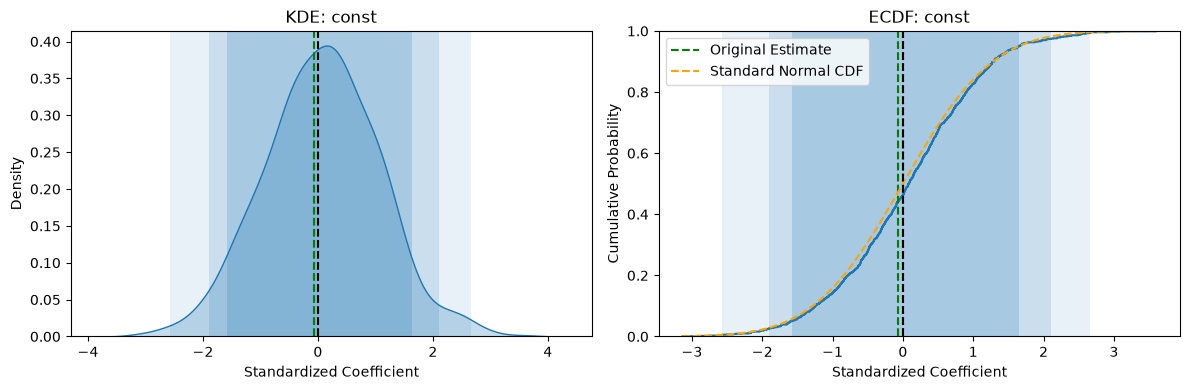

90% Confidence Interval for TotRms.AbvGrd: [-1.4958, 1.6531]
95% Confidence Interval for TotRms.AbvGrd: [-1.8585, 2.0173]
99% Confidence Interval for TotRms.AbvGrd: [-2.6121, 2.6791]


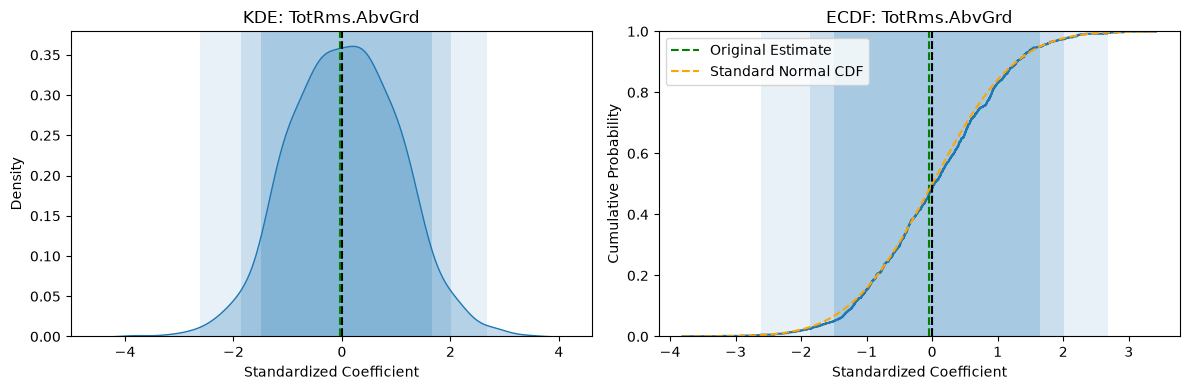

90% Confidence Interval for age: [-1.6428, 1.6000]
95% Confidence Interval for age: [-2.0022, 1.9389]
99% Confidence Interval for age: [-2.6348, 2.5193]


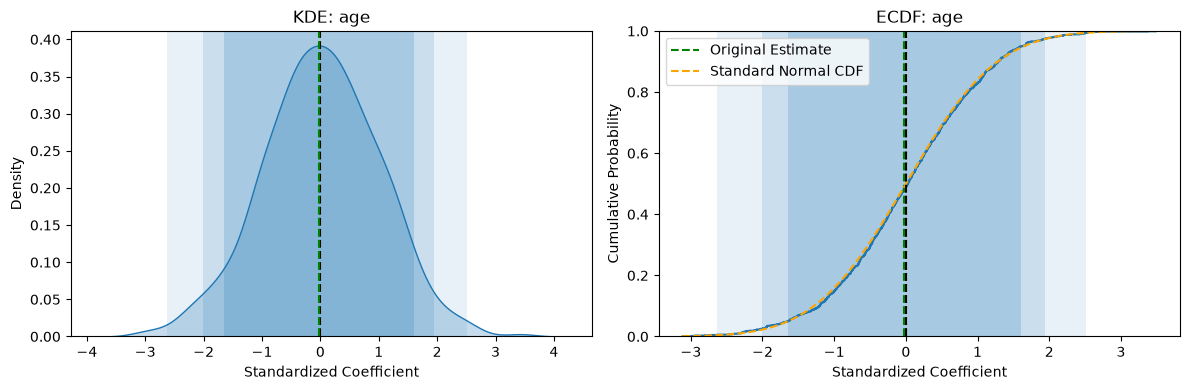

90% Confidence Interval for area: [-1.6813, 1.5130]
95% Confidence Interval for area: [-2.0803, 1.7709]
99% Confidence Interval for area: [-2.7008, 2.5936]


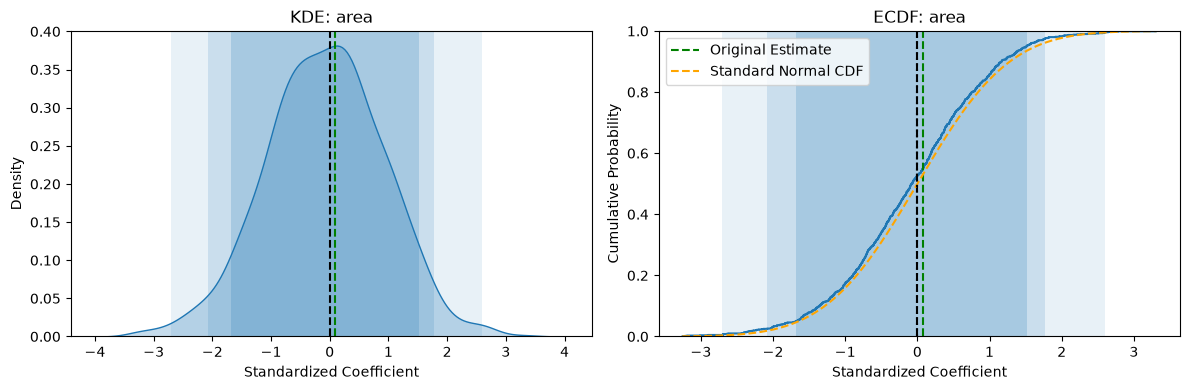

90% Confidence Interval for Full.Bath_1: [-1.6395, 1.6615]
95% Confidence Interval for Full.Bath_1: [-1.9312, 1.9573]
99% Confidence Interval for Full.Bath_1: [-2.6376, 2.6532]


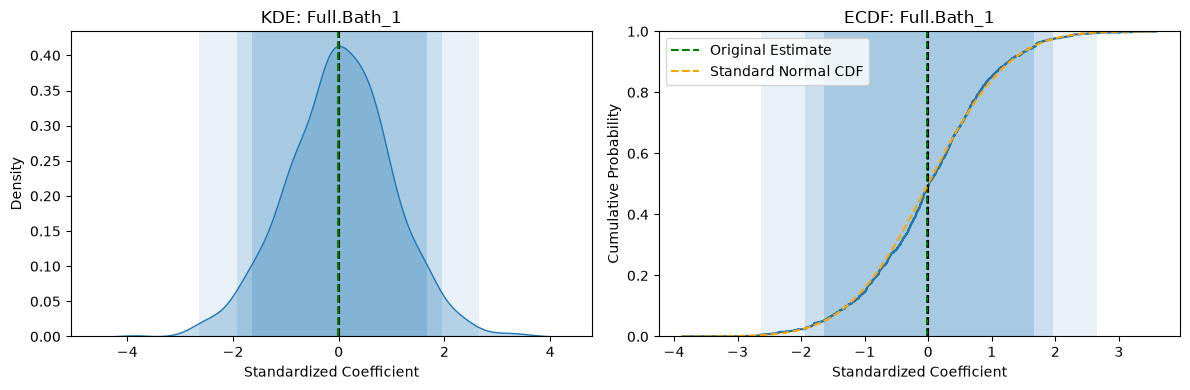

90% Confidence Interval for Full.Bath_2: [-1.6155, 1.6578]
95% Confidence Interval for Full.Bath_2: [-1.9614, 1.9884]
99% Confidence Interval for Full.Bath_2: [-2.6184, 2.7919]


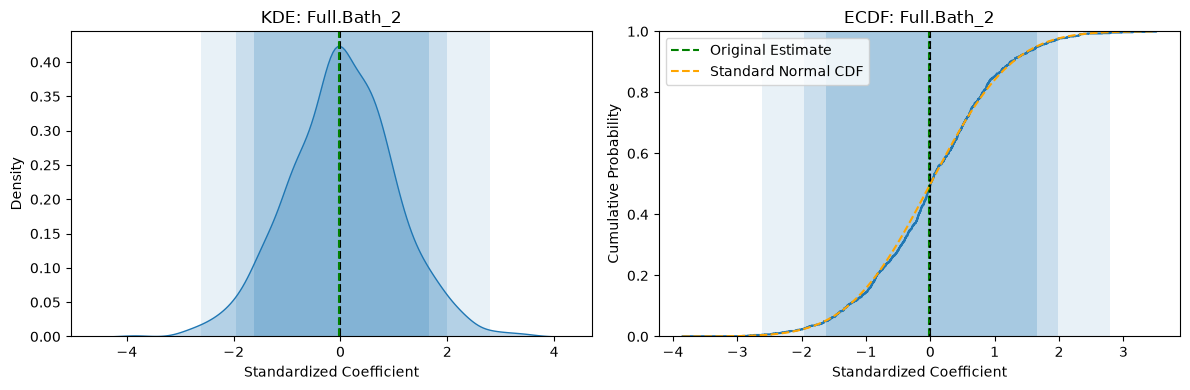

90% Confidence Interval for Full.Bath_3: [-1.5787, 1.6883]
95% Confidence Interval for Full.Bath_3: [-1.8972, 2.0297]
99% Confidence Interval for Full.Bath_3: [-2.5566, 2.8840]


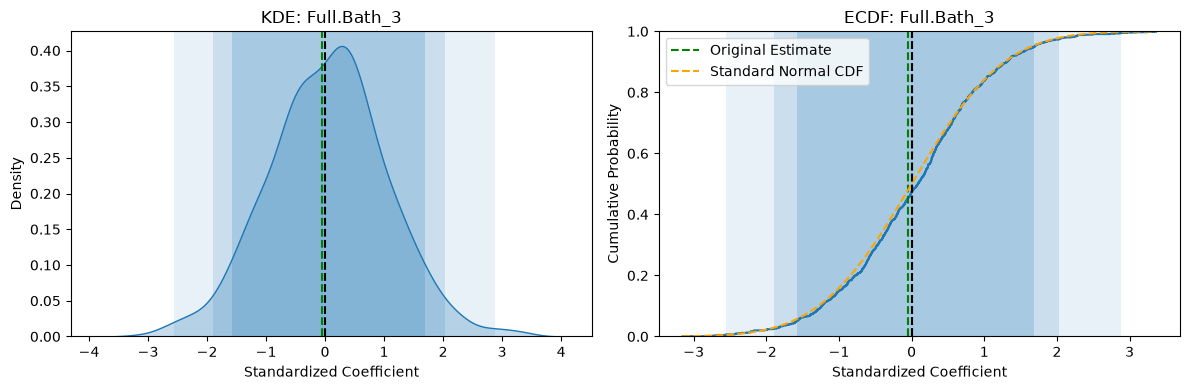

90% Confidence Interval for Full.Bath_4: [-1.4708, 1.7888]
95% Confidence Interval for Full.Bath_4: [-1.8816, 2.4152]
99% Confidence Interval for Full.Bath_4: [-2.4731, 2.5719]


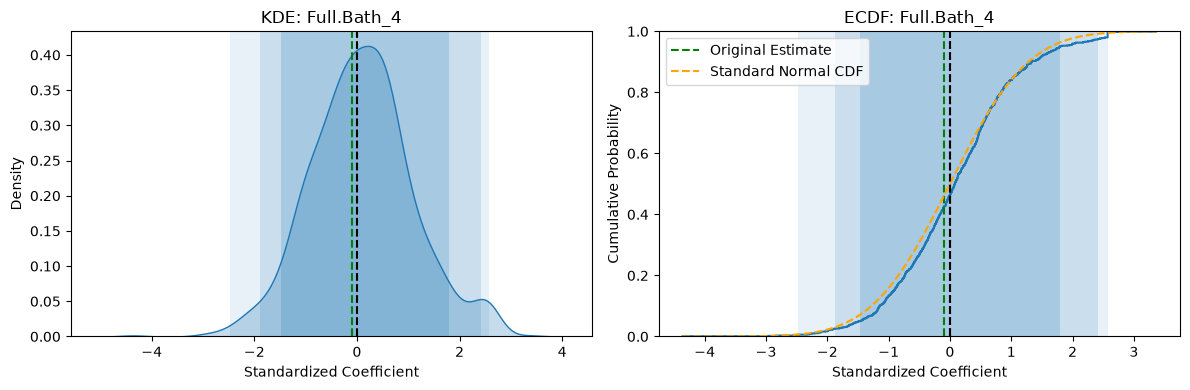

In [12]:
vars = X.columns.to_list()

for idx, var in enumerate(vars):
    sample = results[:, idx]
    mean = np.mean(sample)
    standard_error = np.std(sample, ddof=1)
    z = (sample - beta_hat[idx]) / standard_error
    z_original = (beta_hat[idx] - mean) / standard_error
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # KDE
    sns.kdeplot(z, fill=True, ax=ax[0])
    ax[0].axvline(0, color='black', linestyle='--')
    ax[0].set_title(f'KDE: {var}')
    ax[0].set_xlabel('Standardized Coefficient')
    ax[0].set_ylabel('Density')
    ax[0].axvline(z_original, color='green', linestyle='--',
        label='Original Estimate')
    # ECDF
    sns.ecdfplot(z, ax=ax[1])
    ax[1].axvline(0, color='black', linestyle='--')
    ax[1].set_title(f'ECDF: {var}')
    ax[1].set_xlabel('Standardized Coefficient')
    ax[1].set_ylabel('Cumulative Probability')
    ax[1].set_ylim(0, 1)
    ax[1].axvline(z_original, color='green', linestyle='--',
        label='Original Estimate')
    # Fitted normal CDF
    x_grid = np.linspace(z.min(), z.max(), 500)
    ax[1].plot(
        x_grid,
        norm.cdf(x_grid),
        color='orange',
        linestyle='--',
        label='Standard Normal CDF'
    )

    ax[1].axvline(0, color='black', linestyle=':')
    ax[1].set_title(f'ECDF: {var}')
    ax[1].set_xlabel('Standardized Coefficient')
    ax[1].set_ylabel('Cumulative Probability')
    ax[1].set_ylim(0, 1)
    ax[1].legend()

    # Percentile bootstrap confidence intervals
    ci90 = np.quantile(z, [.05, .95])
    ci95 = np.quantile(z, [.025, .975])
    ci99 = np.quantile(z, [.005, .995])

    ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

    L = np.quantile(z, .05)
    U = np.quantile(z, .95)
    print(f'90% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
    L = np.quantile(z, .025)
    U = np.quantile(z, .975)
    print(f'95% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
    L = np.quantile(z, .005)
    U = np.quantile(z, .995)
    print(f'99% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')

    plt.tight_layout()
    plt.show()

## But Wait
- After $z$-score normalizing, we got roughly the same picture, over and over
- If we get basically the same picture every time, and the bootstrap ECDF and the standard Normal align almost perfectly, then can't we just approximate the sampling distribution of $Z$-scores by a standard Normal?
- This is the basic logic behind classical asymptotic inferential statistics: If the $z$-score normalized densities of "most things" appear to follow the bell curve, let's just use the bell curve to construct CIs and conduct hypothesis tests?

99% interval: [-2.5758, 2.5758]
95% interval: [-1.9600, 1.9600]
90% interval: [-1.6449, 1.6449]


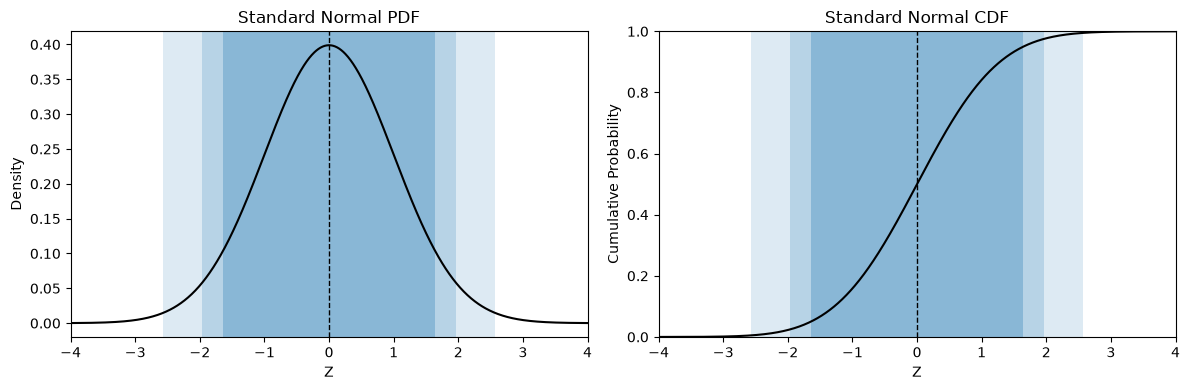

In [13]:
x = np.linspace(-4, 4, 1000)
pdf = norm.pdf(x)
cdf = norm.cdf(x)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Standard normal PDF and CDF
ax[0].plot(x, pdf, color='black', linewidth=1.5)
ax[1].plot(x, cdf, color='black', linewidth=1.5)

# Nested confidence regions: largest first
for confidence, alpha in [(0.99, 0.15),
                          (0.95, 0.20),
                          (0.90, 0.30)]:

    z = norm.ppf((1 + confidence) / 2)
    mask = np.abs(x) <= z
    ax[0].axvspan(-z, z, alpha=alpha)
    # Shade central interval under CDF
    ax[1].axvspan(-z, z, alpha=alpha)
    print(f'{confidence:.0%} interval: [{-z:.4f}, {z:.4f}]')

# Reference at zero
for a in ax:
    a.axvline(0, color='black', linestyle='--', linewidth=1)
    a.set_xlim(-4, 4)

ax[0].set_title('Standard Normal PDF')
ax[0].set_xlabel('Z')
ax[0].set_ylabel('Density')

ax[1].set_title('Standard Normal CDF')
ax[1].set_xlabel('Z')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## The Central Limit Theorem
- Why is this happening?
- **Central Limit Theorem**: Let $[X_1, X_2, ..., X_N]$ be a sample of IID random variables, each with mean $\mu$ and variance $\sigma^2$. Then for the sample mean $\bar{X}_n = \sum_{i=1}^N x_i/N$, as $N$ goes to infinity, 
$$
\frac{\bar{X}_n - \mu}{\sigma/\sqrt{n}} \rightarrow N(0,1)
$$
- This is what we observed above: For a big enough sample, that quantity is roughly normal
- We replace $\bar{X}_n$ by our parameter estimate, and $\sigma/\sqrt{n}$ by the Standard Error of the parameter or the Standard Deviation of the Sampling Distribution (do not divide by $\sqrt{n}$ again, it's baked into the bootstrap estimate)
- For many of the quantities we study, there is a sum of IID random variables happening somewhere, to which the CLT applies
- You can spend your adult life studying this and adjacent ideas

## Perhaps Memorize These

- Instead of taking the quantiles of our bootstrap sample, we can take the quantiles of the standard Normal distribution, then invert the $z$-score normalization to get our confident intervals:

| Confidence | Lower bound | Upper bound | Level ($\alpha$) |
|---|---:|---:| ---:|
| 90% | −1.645 | +1.645 | .10 |
| 95% | −1.960 | +1.960 | .05 |
| 99% | −2.576 | +2.576 | .01 |

So the 90% CI interval comes from this bound:
$$
\left| \frac{\beta_0 - \hat{\beta}}{\widehat{\text{SE}}(\hat{\beta})} \right| \le 1.645
$$
or
$$
\hat{\beta} - 1.645 \times \widehat{\text{SE}}(\hat{\beta}) \le \beta_0 \le \hat{\beta} + 1.645 \times \widehat{\text{SE}}(\hat{\beta})
$$

## Constructing Confidence Intervals
- 90% CI:
$$
( \hat{\beta} - 1.645 \times \widehat{\text{SE}}(\hat{\beta}) \quad , \quad \hat{\beta} + 1.645 \times \widehat{\text{SE}}(\hat{\beta}) )
$$
- 95% CI:
$$
( \hat{\beta} - 1.960 \times \widehat{\text{SE}}(\hat{\beta}) \quad , \quad \hat{\beta} + 1.960 \times \widehat{\text{SE}}(\hat{\beta}) )
$$
- 99% CI:
$$
( \hat{\beta} - 2.576 \times \widehat{\text{SE}}(\hat{\beta}) \quad , \quad \hat{\beta} + 2.576 \times \widehat{\text{SE}}(\hat{\beta}) )
$$

## Connection with Hypothesis Testing
- We define the **null hypothesis**
$$
H_0 : \beta_0 = z
$$
and the **alternative hypothesis**
$$
H_A : \beta_0 \neq z
$$
and specify a **confidence level**, typically .90/.95/.99.

- If $z$ is in the confidence interval, we fail to reject the null; otherwise, we reject the null.
- The value $z$ is very often zero, and we're testing the hypothesis that the parameter takes the value 0.
- We often "secretly want" to reject the null, finding evidence in the favor of the alternative, that the true value of the parameter is not 0

## Example
- You run a regression, and get a coefficient of $5$ with a standard error of $2$ for a key coefficient
- Then the 90% CI is $( 5 - 1.645 \times 2, 5 + 1.645 \times 2) = (1.71, 8.29)$
- Then the 95% CI is $( 5 - 1.960 \times 2, 5 + 1.960 \times 2) = (1.08, 8.92)$
- Then the 99% CI is $( 5 - 2.576 \times 2, 5 + 2.576 \times 2) = (-.15, 10.15)$
- For which levels of confidence is a statistically significant difference from 0 detected?

## Exercise

- You run a regression, and get a coefficient of $10$ with a standard error of $5$ for a key coefficient
- Compute 90/95/99% confidence intervals for the coefficient
- For which levels of confidence is a statistically significant difference from 0 detected?

## What is a Confidence Interval?
- Suppose our estimator is approximately normally distributed:
$$
\frac{\hat{\beta} - \beta_0}{\widehat{\text{SE}}(\hat{\beta})} \sim N(0,1)
$$
- Choose a **critical value** $c$ such that:
$$
\text{pr}\left[ \left| \dfrac{\hat{\beta}-\beta_0}{\widehat{\text{SE}}(\hat{\beta})} \right| \le c \right] = 1 - \alpha
$$
- What is random? $\hat{\beta}$ is a random function of the data. What is fixed? The unknown parameter $\beta_0$ is fixed. This is very, very confusing. The intervals are random functions of data, the parameter is fixed.
- Rearrange to get:
$$
\text{pr}_{\hat{\beta}}\left[ \hat{\beta} - c \times \widehat{\text{SE}}(\hat{\beta}) \le \beta_0 \le \hat{\beta} + c \times \widehat{\text{SE}}(\hat{\beta}) \right] = 1 - \alpha
$$
- This is a statistical reliability claim, not a probability assigned to the unknown parameter value, $\beta_0$

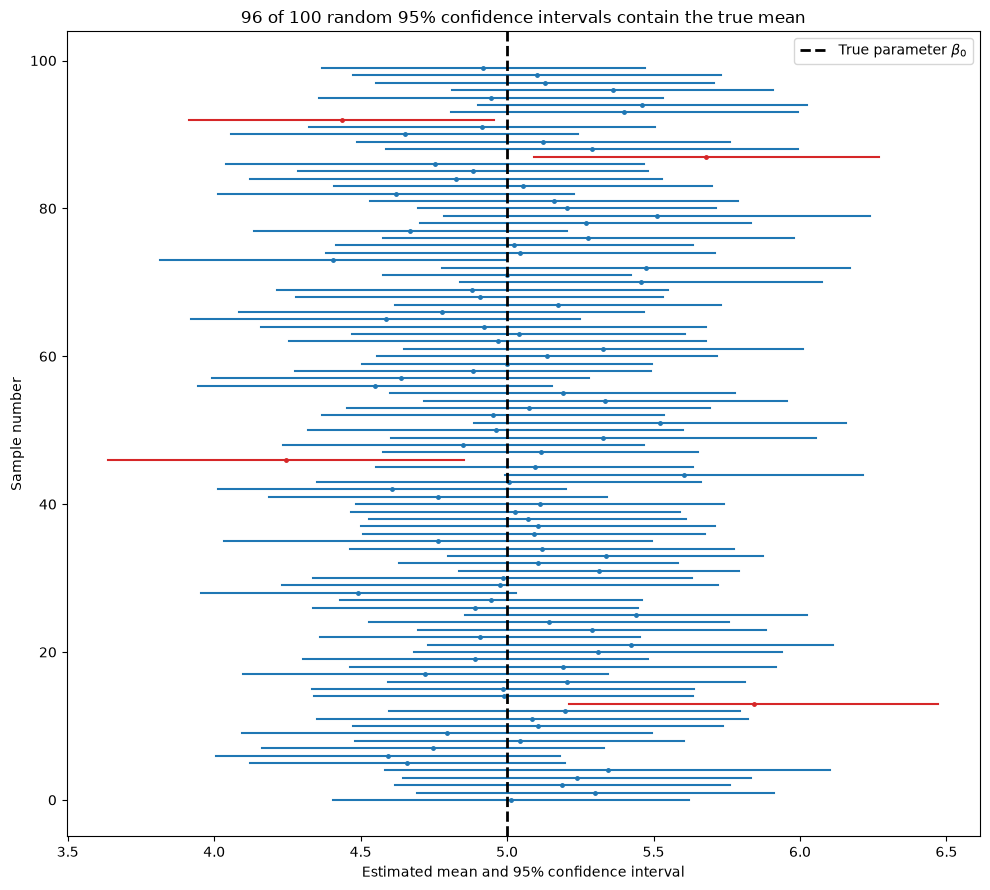

Coverage: 96.0%


In [14]:
rng = np.random.default_rng(100)

# Population and sampling parameters
beta_0 = 5.0             # True population mean (fixed!)
sigma = 2.0              # Population standard deviation
n = 40                   # Observations per sample
R = 100                  # Number of independent samples
c = 1.96                 # 95% confidence interval

# Generate R independent samples
X = rng.normal(beta_0, sigma, size=(R, n))

# Estimate the mean and its standard error for each sample
beta_hat = X.mean(axis=1)
se_hat = X.std(axis=1, ddof=1) / np.sqrt(n)

# Construct confidence intervals
lower = beta_hat - c * se_hat
upper = beta_hat + c * se_hat

# Which intervals contain the true parameter?
covers = (lower <= beta_0) & (beta_0 <= upper)

# Plot
fig, ax = plt.subplots(figsize=(10, 9))

for i in range(R):
    color = 'tab:blue' if covers[i] else 'tab:red'
    ax.plot([lower[i], upper[i]], [i, i], color=color, lw=1.5)
    ax.plot(beta_hat[i], i, '.', color=color, markersize=5)

ax.axvline(beta_0, color='black', linestyle='--',
           linewidth=2, label=r'True parameter $\beta_0$')

ax.set_xlabel(r'Estimated mean and 95% confidence interval')
ax.set_ylabel('Sample number')
ax.set_title(f'{covers.sum()} of {R} random 95% confidence intervals contain the true mean')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Coverage: {covers.mean():.1%}")

## CI to Hypothesis Test
- If we hypothesize $\beta_0$ to take some value $z$, this becomes a **hypothesis test**: Is the hypothesized value $z$ in the interval or not?
$$
\text{pr}_{\hat{\beta}, \text{ when } \beta_0 = z}\left[ \hat{\beta} - c \times \text{SE}(\hat{\beta}) \le z \le \hat{\beta} + c \times \text{SE}(\hat{\beta}) \right] \approx 1 - \alpha
$$
- This is the abstract version of our question: Is $z$ (often 0) outside the CI? If so, reject $H_0$; if it is inside the CI, fail to reject $H_0$.
- If $z$ really were the parameter value, this procedure would exclude it about 10/5/1% of the time for a 90/95/99% confidence interval (this is what **confidence** is)

## The CI is not...
- This is just not $\text{pr}_{\beta_0}[ |\hat{\beta}-\beta_0| \le c ]$ --- The parameter $\beta_0$ is fixed but unknown, not random
- If $\beta_0$ was random, and had a distribution associated with it, then you'd use Bayes' Rule to observe data and update that distribution
- We often say things like, "Gravity is $-9.81 m/s^2$". We don't often say things like, "Gravity is normally distributed with mean $-9.81 m/s^2$ and standard deviation $.0051$"
- If you **did** talk like that, you'd be a Bayesian Statistician, and we'll talk about Bayesian Statistics at the end of the course

## The CI is...
- A set of parameter values that our data do not allow us to reject, using a procedure designed to exclude the true parameter only a specified fraction of the time (the Type 1 error probability).
- Given our observed estimate and its uncertainty, which hypothetical values of the true parameter could we reasonably rule out? (probabilistic reductio ad absurdum: given the hypothesis, what's the probability of observing data that give results at least as extreme as those we got?)
- If we repeatedly sampled data and constructed a new confidence interval each time, approximately 90/95/99% of those intervals would contain the fixed, unknown parameter $\beta_0$ (the bootstrapping connection is the literal repeated sampling)

## Standard Errors
- The **standard error is the standard deviation of the sampling distribution**. These are important but difficult to understand, because the data and estimator create the standard error
- It often shows up in formulas as "$\sigma/\sqrt{n}$", but that can be somewhat confusing: The standard error is always the standard deviation of the sampling distribution, whatever that is (sometimes it's $\sigma/\sqrt{n}$ or $p(1-p)/\sqrt{n}$ or whatever: It depends on the estimator)
- In these notes, we're using the standard deviation of the bootstrap sample as an estimate of the standard error of the sampling distribution,
$$
\widehat{\text{SE}}(\hat{\beta}) = \sqrt{ \frac{1}{R-1}\sum_{b=1}^R (\hat{\beta}_b-\bar{\beta}_{\text{boot}})^2}
$$
and doing the standard $Z$/Normal-version of bootstrapping
$$
Z_b = \frac{\hat{\beta}_b - \hat{\beta}}{\widehat{\text{SE}}(\hat{\beta})}
$$

## Exercise

- Load the Metabric breast cancer dataset, and describe/plot `Overall Survival (Months)`.
- Describe a strategy for selecting variables that you'll use to predict `Overall Survival (Months)`, then implement your strategy and run your regression.
- Construct 90/95/99% non-parametric Bootstrap confidence intervals for the coefficients of your regression, as well as ones based on the Normal approximation using the standard deviation of the bootstrap sample as the standard error of the sampling distribution. How do they compare?
- Which variables are statistically significant, and at what levels?

## Five Things to Think About

1. The parameter is fixed but unknown. We're trying to learn something about a property of the population.
2. Our estimates/confidence intervals are random variables of the data. Different samples produce different estimates, even for the same population doesn't change.
3. The standard error measures variability in our estimators, and botstrapping gives us a practical way to estimate it.
4. The confidence interval translates variability into uncertainty about the parameter. Under the Normal approximation, that's $(\hat{\beta}\pm c \times \widehat{\mathrm{SE}})$. A hypothesized value outside the corresponding interval is rejected as implausible give the data and estimator.
5. The Bootstrap and the CLT are different approaches to understanding the underlying sampling distribution and making inferences about it, with their own strengths and weaknesses.